# Session 16 lab: Brief, critique, revise

<p class="lead">
Turn a finished analysis into a one-page brief and one figure, prepare your own capstone briefing with the questions you expect, critique a classmate's briefing with the feedback rubric, plan your revision, and practise answering three tough executive questions with evidence.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/16_executive_briefings_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

> *Operations director: "I have ten minutes before the leadership meeting. Tell me what you want me to approve, why, how sure you are, and what we will watch afterwards. If they ask me a hard question, I need to be able to answer it."*

> **About the data**
>
> `shipments.csv` is **synthetic** teaching data generated by the course for a fictional retailer, with fictional warehouses and carriers. The cutoff is 2025-12-31. In the independent tasks you switch to **your own** capstone, which may use other course datasets; keep each finding in its own context.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Turn a provided analysis into a one-page brief and one figure | G1–G3 |
| **Independent tasks** | Your own briefing, a peer critique and a revision plan | I1–I5 |
| **Challenge** | Answer three tough executive questions in writing | C1 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Extract the few facts an executive needs from a longer analysis, each with its context.
2. Write a one-page brief with the recommendation first.
3. Design one summary figure with a so-what title, a highlighted comparison and intervals.
4. Structure your own briefing and prepare answers to the questions you expect.
5. Critique a briefing with the rubric, with specific comments.
6. Turn feedback into a prioritised revision plan.
7. Answer challenge questions with evidence, honest uncertainty and clear limits.

**Evidence you keep:** your one-page brief and summary figure, your briefing outline and anticipated-questions table, the rubric critique you gave and received, your revision plan, and your written answers to the three questions.

---

## Before you start

- Read the [Session 16 lecture](16_executive_briefings_lecture.md).
- Have your capstone register, outline and trade-off table from the [Session 15 lab](15_capstone_studio_lab.md) to hand.

---

## Guided practice

### G1 (Core): The provided analysis

Run the setup cell, then the cell after it. It rebuilds the Session 11 service measures and collects the **facts** a brief needs into one table, each with its denominator, period and comparison.

In [1]:
# Operations data setup (synthetic). Run this cell first.
# Downloads the course's synthetic shipment data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

OPERATIONS_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/operations-v1/"
OPERATIONS_SHA256 = {"shipments.csv": "7b5c0860beb2a16ba4f84a3dd0b5bdf9d88e968b720c6541f1dcb7d688c75687"}
OPERATIONS_DIR = os.environ.get("COURSE_OPERATIONS_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_shipments():
    """Load operations-v1 shipments: one row per shipment, known at the end of 2025-12-31."""
    if OPERATIONS_DIR:
        with open(os.path.join(OPERATIONS_DIR, "shipments.csv"), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(OPERATIONS_URL + "shipments.csv").read()
    if hashlib.sha256(data).hexdigest() != OPERATIONS_SHA256["shipments.csv"]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["dispatch_date", "promised_date", "delivered_date"])


print("Operations setup complete.")

Operations setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})


def add_service_columns(df, cutoff=CUTOFF):
    """Session 11 contract: population at the cutoff, and on time = delivered on or before the promise."""
    out = df.copy()
    out["population"] = np.select(
        [out["status"] == "canceled", out["promised_date"].isna(), out["promised_date"] > cutoff],
        ["canceled", "unknown promise", "not yet due"], default="due")
    out["on_time"] = out["delivered_date"].notna() & (out["delivered_date"] <= out["promised_date"])
    out["pending"] = out["delivered_date"].isna() & (out["status"] != "canceled")
    return out


def rate_ci(k, n, z=1.96):
    """Rate with a normal-approximation 95% interval."""
    p = k / n
    half = z * np.sqrt(p * (1 - p) / n)
    return p, p - half, p + half


shipments = load_shipments()
s = add_service_columns(shipments)
due = s[s["population"] == "due"].copy()
due["promised_month"] = due["promised_date"].dt.to_period("M").dt.to_timestamp()
monthly = due.groupby("promised_month").agg(due=("on_time", "size"), on_time=("on_time", "sum"))
monthly["rate"] = monthly["on_time"] / monthly["due"]

dec = due[due["promised_month"] == "2025-12-01"]
earlier = due[due["promised_month"] < "2025-11-01"]
by_carrier_dec = dec.groupby("carrier")["on_time"].agg(due="size", rate="mean")
worst = by_carrier_dec["rate"].idxmin()
p, low, high = rate_ci(int(dec["on_time"].sum()), len(dec))

facts = pd.DataFrame([
    ("Year on-time rate", f"{due['on_time'].mean():.0%}", f"{len(due):,} due shipments", "Promised in 2025"),
    ("December on-time rate", f"{p:.0%} (95% interval {low:.0%} to {high:.0%})", f"{len(dec):,} due shipments",
     "Promised in December 2025"),
    ("Jan-Oct on-time rate", f"{earlier['on_time'].mean():.0%}", f"{len(earlier):,} due shipments", "Promised Jan-Oct 2025"),
    (f"{worst} in December", f"{by_carrier_dec.loc[worst, 'rate']:.0%}", f"{int(by_carrier_dec.loc[worst, 'due'])} due shipments",
     "Promised in December 2025"),
    ("Due shipments still pending", f"{int(due['pending'].sum())}", "due, not delivered", "At the cutoff, 2025-12-31"),
    ("Excluded: unknown promise date", f"{int((s['population'] == 'unknown promise').sum())}", "shipments", "Listed in appendix"),
], columns=["fact", "value", "out of", "period"]).set_index("fact")
facts

,value,out of,period
fact,,,
Year on-time rate,82%,"5,742 due shipments",Promised in 2025
December on-time rate,55% (95% interval 52% to 59%),790 due shipments,Promised in December 2025
Jan-Oct on-time rate,88%,"4,325 due shipments",Promised Jan-Oct 2025
ParcelOne in December,24%,288 due shipments,Promised in December 2025
Due shipments still pending,157,"due, not delivered","At the cutoff, 2025-12-31"
Excluded: unknown promise date,12,shipments,Listed in appendix


Every value in the facts table comes from code, with the context it needs. The brief will use only a few of them; the rest go to the appendix.

### G2 (Core): Draft the one-page brief

The cell below drafts the brief from the facts, in executive order: recommendation, reasons, trade-offs, uncertainty, next steps. Read it, then change the wording to make it yours.

> **Your turn:** change the code in the next cell and run it again.

In [3]:
# 1. Run the cell and read the draft aloud. Does the first sentence say what to approve?
# 2. Change owner and review_month. Rewrite one reason so it is shorter and still has its number in context.
# 3. Delete anything a director would not miss. A brief that fits on one page is the goal.
owner = "Head of logistics"
review_month = "February 2026"

brief = f"""
RECOMMENDATION: Approve a review of {worst}'s peak-season capacity and contract terms, led by the {owner.lower()},
with a decision on next year's peak plan by {review_month}.

WHY
1. Promises collapsed in the peak: {p:.0%} of {len(dec):,} December promises were kept, against
   {earlier['on_time'].mean():.0%} for January to October.
2. One carrier fell furthest: {worst} kept {by_carrier_dec.loc[worst, 'rate']:.0%} of its
   {int(by_carrier_dec.loc[worst, 'due'])} December promises; the other carriers fell less.
3. The problem is not over: {int(due['pending'].sum())} due shipments were still undelivered at the cutoff.

TRADE-OFFS: switching volume away from {worst} may cost more per parcel; a review costs little and keeps options open.

UNCERTAINTY AND LIMITS: December's rate lies between about {low:.0%} and {high:.0%} (95% interval); the drop is far
too large to be chance. The data show when and where promises failed, not why.

NEXT STEPS: monthly on-time rate by carrier, reviewed in {review_month}; appendix holds definitions and checks.
"""
print(brief)
print(f"Words: {len(brief.split())} (aim for under about 250)")


RECOMMENDATION: Approve a review of ParcelOne's peak-season capacity and contract terms, led by the head of logistics,
with a decision on next year's peak plan by February 2026.

WHY
1. Promises collapsed in the peak: 55% of 790 December promises were kept, against
   88% for January to October.
2. One carrier fell furthest: ParcelOne kept 24% of its
   288 December promises; the other carriers fell less.
3. The problem is not over: 157 due shipments were still undelivered at the cutoff.

TRADE-OFFS: switching volume away from ParcelOne may cost more per parcel; a review costs little and keeps options open.

UNCERTAINTY AND LIMITS: December's rate lies between about 52% and 59% (95% interval); the drop is far
too large to be chance. The data show when and where promises failed, not why.

NEXT STEPS: monthly on-time rate by carrier, reviewed in February 2026; appendix holds definitions and checks.

Words: 148 (aim for under about 250)


Now write the brief in your own words in the template below. Double-click the cell to edit it, replace each `[...]`, and keep it to one page. Take every number from the facts table or the draft above; do not type a number you did not compute.

> **One-page brief template**
>
> **Title (the recommendation as a sentence):** [...]
>
> **Recommendation** (two or three sentences: what, who owns it, by when): [...]
>
> **Why** (two or three findings, each with its number, denominator, period and comparison):
> 1. [...]
> 2. [...]
> 3. [...]
>
> **Trade-offs and risks:** [...]
>
> **Uncertainty and limits** (a range in plain words; what the data cannot show): [...]
>
> **Next steps and monitoring measure** (measure, owner, review date): [...]
>
> **Appendix pointers** (definitions, checks, data version): [...]

### G3 (Core): One summary figure

The brief needs **one** figure that carries the message. The cell below draws it: a so-what title built from the data, December highlighted, the earlier rate as a reference line, 95% intervals and a caption with the definition and source.

> **Your turn:** change the code in the next cell and run it again.

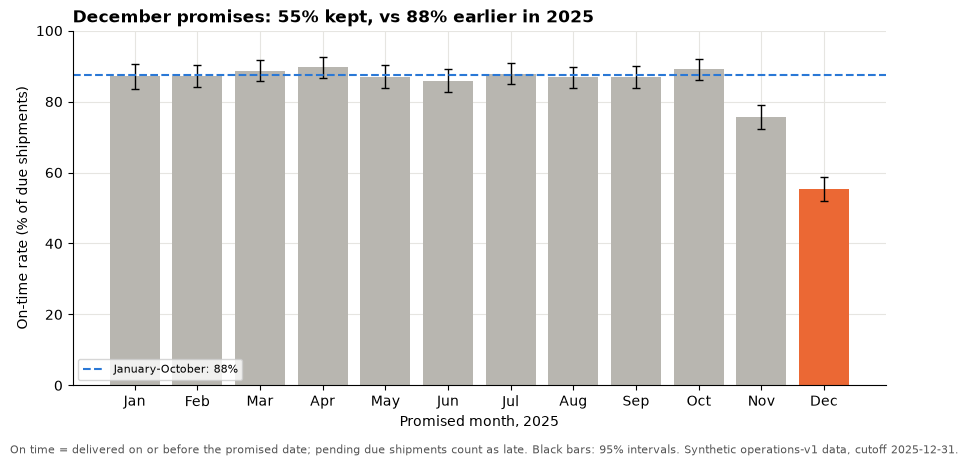

In [4]:
# 1. Run the cell. Cover the title with your hand: does the chart still make its point?
# 2. Change highlight_month to "2025-11-01". Should November be highlighted too? Rewrite the title if so.
# 3. Change show_intervals to False. What does the reader lose?
highlight_month = "2025-12-01"
show_intervals = True

ci = pd.DataFrame([rate_ci(k, n) for k, n in zip(monthly["on_time"], monthly["due"])],
                  columns=["rate", "low", "high"], index=monthly.index)
reference = earlier["on_time"].mean()
highlight = ci.loc[highlight_month, "rate"]
x = np.arange(len(ci))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x, ci["rate"] * 100, color=["#eb6834" if m == pd.Timestamp(highlight_month) else "#b8b6b0" for m in ci.index])
if show_intervals:
    ax.errorbar(x, ci["rate"] * 100, yerr=[(ci["rate"] - ci["low"]) * 100, (ci["high"] - ci["rate"]) * 100],
                fmt="none", ecolor="black", elinewidth=1, capsize=3)
ax.axhline(reference * 100, color="#2a78d6", linestyle="--", linewidth=1.5, label=f"January-October: {reference:.0%}")
ax.set_xticks(x, ci.index.strftime("%b"))
ax.set_ylim(0, 100)
ax.set_title(f"{pd.Timestamp(highlight_month):%B} promises: {highlight:.0%} kept, vs {reference:.0%} earlier in 2025")
ax.set_xlabel("Promised month, 2025")
ax.set_ylabel("On-time rate (% of due shipments)")
ax.legend(fontsize=8, loc="lower left")
fig.text(0.01, -0.02, "On time = delivered on or before the promised date; pending due shipments count as late. "
         "Black bars: 95% intervals. Synthetic operations-v1 data, cutoff 2025-12-31.", fontsize=8, color="#555555")
fig.tight_layout()
plt.show()

---

## Independent tasks

Switch to **your own capstone**. The default code in each cell uses the operations case so that it runs; replace its content with yours.

### I1 (Core): Structure your briefing

Fill in your briefing structure. The check below enforces the executive order: a recommendation that is an action, three to five slides (or one page), two or three findings, uncertainty, an owner and a monitoring measure.

> **Your turn:** change the code in the next cell and run it again.

In [5]:
# 1. Run the cell with the default structure and read the checks.
# 2. Replace every value with your own capstone briefing.
# 3. Read your recommendation alone. Would a director know what to approve?
briefing = {
    "format": "slides",                       # "slides" or "one page"
    "recommendation": f"Approve a review of {worst}'s peak capacity, owned by the head of logistics, decided by February",
    "findings": [
        f"December promises kept: {p:.0%} vs {earlier['on_time'].mean():.0%} earlier in the year",
        f"{worst} fell furthest in December",
        "Due shipments still pending at the cutoff",
    ],
    "slides": ["Decision and recommendation", "Summary figure", "Trade-offs", "Uncertainty and limits", "Next steps"],
    "uncertainty": f"December rate between about {low:.0%} and {high:.0%}; shows where and when, not why",
    "owner": "Head of logistics",
    "monitoring_measure": "Monthly on-time rate by carrier, due population",
}

ACTION_VERBS = ("approve", "fund", "review", "stop", "start", "move", "invest", "pilot", "renegotiate", "hire", "choose")
briefing_checks = {
    "recommendation starts with an action verb": briefing["recommendation"].lower().startswith(ACTION_VERBS),
    "two or three findings": 2 <= len(briefing["findings"]) <= 3,
    "three to five slides (or one page)": briefing["format"] == "one page" or 3 <= len(briefing["slides"]) <= 5,
    "recommendation comes first": briefing["format"] == "one page" or "recommend" in briefing["slides"][0].lower(),
    "uncertainty stated": len(briefing["uncertainty"]) > 20,
    "owner and monitoring measure named": bool(briefing["owner"]) and bool(briefing["monitoring_measure"]),
}
for i, slide in enumerate(briefing["slides"], start=1):
    print(f"Slide {i}: {slide}")
print()
for name, ok in briefing_checks.items():
    print("PASS" if ok else "FAIL", "-", name)

Slide 1: Decision and recommendation
Slide 2: Summary figure
Slide 3: Trade-offs
Slide 4: Uncertainty and limits
Slide 5: Next steps

PASS - recommendation starts with an action verb
PASS - two or three findings
PASS - three to five slides (or one page)
PASS - recommendation comes first
PASS - uncertainty stated
PASS - owner and monitoring measure named


### I2 (Core): Your summary figure

Make the **one** figure for your briefing. The function below draws a highlighted bar chart with an optional reference line and caption for any monthly (or category) series. Feed it your capstone's key measure.

In [6]:
def summary_figure(values, highlight, title, ylabel, xlabel, caption, reference=None, reference_label=""):
    """One highlighted bar chart with a so-what title, a reference line and a caption."""
    fig, ax = plt.subplots(figsize=(9, 4.5))
    labels = [str(i) for i in values.index]
    ax.bar(labels, values, color=["#eb6834" if i == highlight else "#b8b6b0" for i in values.index])
    if reference is not None:
        ax.axhline(reference, color="#2a78d6", linestyle="--", linewidth=1.5, label=reference_label)
        ax.legend(fontsize=8, loc="upper left")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    fig.text(0.01, -0.02, caption, fontsize=8, color="#555555")
    fig.tight_layout()
    plt.show()

> **Your turn:** change the code in the next cell and run it again.

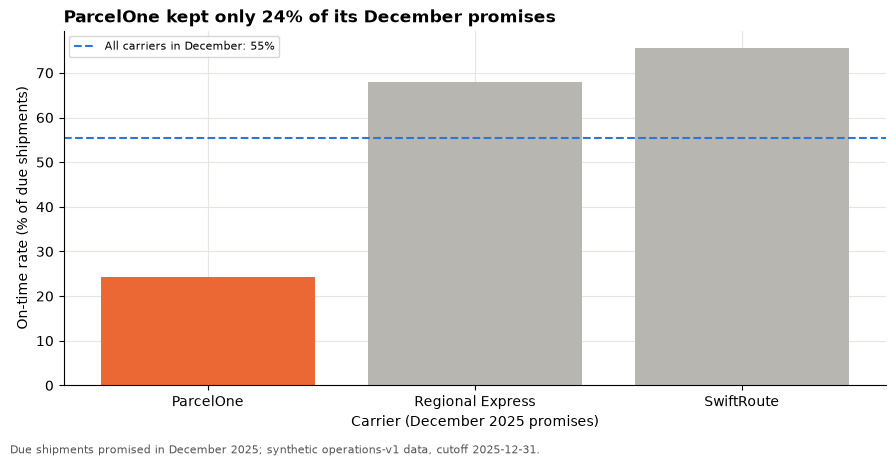

In [7]:
# 1. Run the cell: the default shows December on-time rates by carrier.
# 2. Replace values, highlight, title, labels and caption with your capstone's key measure.
# 3. Write the title as a so-what sentence, and build any number in it from the data (an f-string).
values = (by_carrier_dec["rate"] * 100).sort_values()
summary_figure(
    values=values,
    highlight=worst,
    title=f"{worst} kept only {by_carrier_dec.loc[worst, 'rate']:.0%} of its December promises",
    ylabel="On-time rate (% of due shipments)",
    xlabel="Carrier (December 2025 promises)",
    caption="Due shipments promised in December 2025; synthetic operations-v1 data, cutoff 2025-12-31.",
    reference=dec["on_time"].mean() * 100,
    reference_label=f"All carriers in December: {dec['on_time'].mean():.0%}",
)

### I3 (Core): Anticipated questions

List the questions you expect, with a short answer, the evidence behind it and what would change your mind. Prepare at least **five**, including "How do you know?" and "What would change your mind?".

> **Your turn:** change the code in the next cell and run it again.

In [8]:
# 1. Run the cell and read the default questions and answers.
# 2. Replace them with the questions YOUR audience is most likely to ask about your capstone.
# 3. For each answer, check: is there a number with context, and is the evidence something you actually computed?
questions = pd.DataFrame([
    ("How do you know?", "On-time due shipments / all due shipments; pending ones count as late",
     "Facts table; populations reconcile; operations-v1", "A definition error found in review"),
    ("What would change your mind?", f"{worst} back near its earlier rate at peak volume",
     "Carrier rates by period (lecture appendix table)", "Next peak's carrier results"),
    ("Is it just December?", "November was also below the earlier months", "Monthly rates with intervals (G3)",
     "If November had been normal"),
    ("Is this the carrier's fault?", "The data show where and when, not why", "Carrier x month table",
     "Evidence on volumes agreed with the carrier"),
    ("What does waiting cost?", "Another peak at the same rate would hit the busiest month", "Monthly due volumes",
     "A much smaller peak forecast"),
], columns=["question", "short answer", "evidence", "what would change my mind"])

missing = questions[(questions["evidence"].str.len() < 10) | (questions["what would change my mind"].str.len() < 10)]
print(f"{len(questions)} questions prepared; {len(missing)} without enough evidence or a change-my-mind answer")
questions

5 questions prepared; 0 without enough evidence or a change-my-mind answer


,question,short answer,evidence,what would change my mind
0,How do you know?,On-time due shipments / all due shipments; pen...,Facts table; populations reconcile; operations-v1,A definition error found in review
1,What would change your mind?,ParcelOne back near its earlier rate at peak v...,Carrier rates by period (lecture appendix table),Next peak's carrier results
2,Is it just December?,November was also below the earlier months,Monthly rates with intervals (G3),If November had been normal
3,Is this the carrier's fault?,"The data show where and when, not why",Carrier x month table,Evidence on volumes agreed with the carrier
4,What does waiting cost?,Another peak at the same rate would hit the bu...,Monthly due volumes,A much smaller peak forecast


### I4 (Core): Peer critique with the rubric

Swap briefings with a classmate. Listen to (or read) their briefing, then score it with the feedback rubric from the lecture: a **level** from 1 to 4 for each criterion and a specific **comment**. The default levels and comments only show the style; replace them all.

> **Good comments are specific**
>
> "The December rate has no denominator" helps. "Check your numbers" does not. Comment on the **evidence**, not the person, and end with one next action.

> **Your turn:** change the code in the next cell and run it again.

In [9]:
# 1. Run the cell with the example scores.
# 2. Replace reviewer, author, levels and comments with your critique of your classmate's briefing.
# 3. Write the three feedback lines at the bottom: one strength, one critical issue, one next action.
reviewer, author = "Reviewer name", "Author name"

critique = pd.DataFrame({
    "weight": [15, 20, 15, 15, 10, 15, 10],
    "level": [3, 4, 3, 2, 3, 3, 4],
    "comment": [
        "Decision clear; the review period is not defined",
        "Recomputed the December rate independently: matches",
        "Data version cited; no hand check shown",
        "Interval given, but the chart caption implies the carrier caused the drop",
        "So-what title; legend covers a bar",
        "Owner and measure named; option costs not compared",
        "Recommendation first; answered 'how do you know' with the definition",
    ],
}, index=["Decision framing and metric contracts", "Preparation and analytical correctness",
          "Validation and reproducibility", "Statistical reasoning", "Visual communication",
          "Recommendation, synthesis and limitations", "Executive briefing"])

assert critique["weight"].sum() == 100 and critique["level"].between(1, 4).all()
assert (critique["comment"].str.len() > 15).all(), "every criterion needs a specific comment"
critique["points"] = critique["weight"] * critique["level"] / 4
print(f"Review of {author} by {reviewer}: {critique['points'].sum():.1f} of 100 (feedback only, not a grade)")
print(f"Start the revision with: {critique['level'].idxmin()}")
display(critique)

feedback = {
    "strength": "Recommendation first, with the December rate in context",
    "critical issue": "Causal wording about the carrier in the caption",
    "next action": "Rewrite the caption to describe, and add the carrier x period table to the appendix",
}
for k, v in feedback.items():
    print(f"{k:>15}: {v}")

Review of Author name by Reviewer name: 78.8 of 100 (feedback only, not a grade)
Start the revision with: Statistical reasoning


,weight,level,comment,points
Decision framing and metric contracts,15,3,Decision clear; the review period is not defined,11.25
Preparation and analytical correctness,20,4,Recomputed the December rate independently: ma...,20.00
Validation and reproducibility,15,3,Data version cited; no hand check shown,11.25
Statistical reasoning,15,2,"Interval given, but the chart caption implies ...",7.50
Visual communication,10,3,So-what title; legend covers a bar,7.50
"Recommendation, synthesis and limitations",15,3,Owner and measure named; option costs not comp...,11.25
Executive briefing,10,4,Recommendation first; answered 'how do you kno...,10.00


       strength: Recommendation first, with the December rate in context
 critical issue: Causal wording about the carrier in the caption
    next action: Rewrite the caption to describe, and add the carrier x period table to the appendix


### I5 (Stretch): Your revision plan

Use the critique **you received** to plan your revision. Put the most important change first: anything that affects a **critical number** or an **overclaim** comes before layout.

> **Your turn:** change the code in the next cell and run it again.

In [10]:
# 1. Run the cell with the example plan.
# 2. Replace the rows with the changes from the critique you received.
# 3. Sort by priority. Which change, if skipped, would make your recommendation unsafe to present?
revision = pd.DataFrame([
    ("Causal wording in the figure caption", "Describe when and where; move 'why' to next steps", 1, "Caption has no causal words"),
    ("No hand check in the validation pack", "Recount one week's December shipments by hand", 2, "Hand count matches the code"),
    ("Option costs not compared", "Add a cost row to the trade-off table with a source", 3, "Trade-off table updated"),
    ("Legend covers a bar", "Move the legend", 4, "Figure checked at slide size"),
], columns=["issue", "change", "priority", "evidence it is fixed"]).sort_values("priority")
assert revision["priority"].is_unique, "give each change its own priority"
revision.set_index("priority")

,issue,change,evidence it is fixed
priority,,,
1,Causal wording in the figure caption,Describe when and where; move 'why' to next steps,Caption has no causal words
2,No hand check in the validation pack,Recount one week's December shipments by hand,Hand count matches the code
3,Option costs not compared,Add a cost row to the trade-off table with a s...,Trade-off table updated
4,Legend covers a bar,Move the legend,Figure checked at slide size


---

## Challenge

### C1 (Challenge): Three tough executive questions

In the leadership meeting, three executives ask the questions below. For each one, run the evidence cell, then write a **short spoken answer** (three or four sentences) in the cell after it. A good answer:

1. Answers the question **directly** in the first sentence.
2. Gives **one number with context** from the evidence.
3. States the **limit** honestly, and offers a **next step** if you cannot answer fully.

**Question 1 (finance director): "December is one month. How do you know this isn't just a bad month that happens sometimes?"**

> **Your turn:** change the code in the next cell and run it again.

In [11]:
# Evidence: December against earlier months, with a 95% interval for the difference.
# Change compare_from to "2025-07-01" to compare with July-October only. Does your answer change?
compare_from = "2025-01-01"

base = due[(due["promised_month"] >= compare_from) & (due["promised_month"] < "2025-11-01")]
p1, n1 = dec["on_time"].mean(), len(dec)
p0, n0 = base["on_time"].mean(), len(base)
half = 1.96 * np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
print(f"December {p1:.1%} (n={n1}) vs baseline {p0:.1%} (n={n0})")
print(f"Difference {100 * (p1 - p0):+.1f} points, 95% interval {100 * (p1 - p0 - half):+.1f} to {100 * (p1 - p0 + half):+.1f}")
print(f"Lowest month before November: {monthly.loc[:'2025-10-01', 'rate'].min():.1%}")

December 55.3% (n=790) vs baseline 87.6% (n=4325)
Difference -32.3 points, 95% interval -35.9 to -28.7
Lowest month before November: 85.9%


> **Your answer to question 1:** [Write three or four sentences here. Hint: this data has only one December, so say what that limits.]

**Question 2 (chief executive): "So should we just drop the worst carrier?"**

> **Your turn:** change the code in the next cell and run it again.

In [12]:
# Evidence: each carrier's share of December due shipments and its December rate.
# Change month to "2025-11-01". Is the pattern the same in November?
month = "2025-12-01"

m = due[due["promised_month"] == month]
table = m.groupby("carrier")["on_time"].agg(due="size", rate="mean")
table["share of volume"] = table["due"] / table["due"].sum()
table["late shipments"] = (table["due"] * (1 - table["rate"])).round().astype(int)
table.assign(rate=table["rate"].map("{:.0%}".format), **{"share of volume": table["share of volume"].map("{:.0%}".format)})

,due,rate,share of volume,late shipments
carrier,,,,
ParcelOne,288,24%,36%,218
Regional Express,169,68%,21%,54
SwiftRoute,333,76%,42%,81


> **Your answer to question 2:** [Write three or four sentences here. Hint: what would the other carriers need to absorb, and do we know they could keep their rates at that volume?]

**Question 3 (marketing director): "If we fix delivery, how much extra revenue will we make?"**

> **Your turn:** change the code in the next cell and run it again.

In [13]:
# Evidence: what this dataset can and cannot measure.
print("Columns in shipments.csv:", ", ".join(shipments.columns))
print("Any revenue or order-value column?", any(k in c for c in shipments.columns for k in ("revenue", "value", "sales")))
print(f"Late December shipments: {int((~dec['on_time']).sum())} of {len(dec)}")

Columns in shipments.csv: shipment_id, order_id, warehouse_id, warehouse, carrier_id, carrier, service, dispatch_date, promised_date, delivered_date, status
Any revenue or order-value column? False
Late December shipments: 353 of 790


> **Your answer to question 3:** [Write three or four sentences here. Hint: what does the data contain, what would you need to estimate revenue, and why could you not borrow a number from the marketing or retail datasets?]

---

## Validation checklist

- [ ] Every number in the brief comes from code and has its denominator, period and comparison.
- [ ] The first sentence is a recommendation that names an action, an owner and a time.
- [ ] The summary figure has a so-what title built from the data, a highlight, units, intervals where relevant and a caption.
- [ ] Uncertainty is stated as a range in plain words, with the main assumption.
- [ ] No sentence claims a cause that the data cannot show, or links findings across separate datasets.
- [ ] The anticipated-questions table has evidence and a "what would change my mind" answer for every row.
- [ ] Your critique gives a level and a specific comment for every rubric criterion.
- [ ] Your revision plan puts critical-number and overclaim fixes first.

---

## Exit ticket

1. Write the first sentence of your capstone briefing.
2. Give one number from your capstone with its denominator, period and comparison.
3. How would you answer "What would change your mind?" for your recommendation?
4. What is the difference between a fall of 10 percentage points and a fall of 10%?
5. Which rubric criterion did your peer score lowest, and what is your first revision?

---

## Course reflection

Write half a page in your evidence log:

1. **A corrected error.** Describe one mistake you made during the course (a join, a denominator, a filter, a claim) and how you found and fixed it.
2. **What could change your recommendation.** Name the one piece of evidence that would most change your capstone's recommendation, and how you would collect it.
3. **A transferable method.** Name one method from the course you will use at work, and on what decision.
4. **Next step.** The course continues with the Tableau section, which rebuilds key analyses with the same data and contracts. Which of your analyses would you most like to rebuild there, and why?

---

## Evidence to keep

- [ ] Your facts table and one-page brief (G1–G2), and the summary figure (G3)
- [ ] Your briefing structure with its checks (I1) and your own summary figure (I2)
- [ ] Your anticipated-questions table (I3)
- [ ] The rubric critique you gave (I4) and your revision plan (I5)
- [ ] Your written answers to the three executive questions (C1)
- [ ] Your exit ticket and course reflection